# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# cargar archivos

plans = pd.read_csv("/datasets/plans.csv")
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [5]:
# mostrar las primeras 5 filas de plans
print("=== PLANS ===")
print(plans.head(5))

=== PLANS ===
  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [6]:
# mostrar las primeras 5 filas de users
print("\n=== USERS ===")
print(users.head(5))


=== USERS ===
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [7]:
# mostrar las primeras 5 filas de usage
print("\n=== USAGE ===")
print(usage.head(5))


=== USAGE ===
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
# revisar el número de filas y columnas de cada dataset
print("=== DIMENSIONES (.shape) ===")
print("plans:", plans.shape)
print("users:", users.shape)
print("usage:", usage.shape)

=== DIMENSIONES (.shape) ===
plans: (2, 8)
users: (4000, 8)
usage: (40000, 6)


In [9]:
# inspección de plans con .info()
print("\n=== INFO: PLANS ===")
plans.info()


=== INFO: PLANS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [10]:
# inspección de users con .info()
print("\n=== INFO: USERS ===")
users.info()


=== INFO: USERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
# inspección de usage con .info()
print("\n=== INFO: USAGE ===")
usage.info()


=== INFO: USAGE ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [12]:
# cantidad de nulos para users
print("=== USERS: Cantidad de valores nulos ===")
print(users.isna().sum())
print("\n=== USERS: Proporción de valores nulos ===")
print(users.isna().mean())

=== USERS: Cantidad de valores nulos ===
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

=== USERS: Proporción de valores nulos ===
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [13]:
# cantidad de nulos para usage
print("\n=== USAGE: Cantidad de valores nulos ===")
print(usage.isna().sum())

print("\n=== USAGE: Proporción de valores nulos ===")
print(usage.isna().mean())


=== USAGE: Cantidad de valores nulos ===
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

=== USAGE: Proporción de valores nulos ===
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

- users.city (469 nulos / 11.73%): Falta moderada en una variable segmentadora clave; conviene mantener como nulo o asignar "Desconocida" tras revisar si sigue algún patrón por país o ciudad.

- users.churn_date (3,534 nulos / 88.35%): Alta proporción de nulos porque indica clientes activos sin fecha de baja; se debe conservar como nulo para distinguir usuarios activos de bajas.

- usage.date (50 nulos / 0.13%): Proporción mínima de registros sin fecha; conviene inspeccionar esas filas y dejar como nulo o imputar solo si hay regla clara para no sesgar series temporales.

- usage.duration (22,076 nulos / 55.19%): Faltan más de la mitad de los registros porque probablemente aplica solo a llamadas y no a mensajes; conviene validar contra type y mantener como nulo en eventos que no son llamadas.

- usage.length (17,896 nulos / 44.74%): Ausencia cercana a la mitad de los registros porque probablemente aplica solo a mensajes y no a llamadas; conviene verificar contra type y conservar como nulo cuando el evento no sea mensaje.

Después de tener estas visuales de cómo están los datos, podemos definir que las fechas y la duración de las llamadas son los valores más altos. Sería bueno entender en lenght y duración que es lo que se está contando realmente. Ahora procedemos a la limpieza. 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [14]:
# explorar columnas numéricas de users
# --- COLUMNAS NUMÉRICAS ---
print("=== USERS: Resumen numérico (.describe()) ===")
print(users.describe())

print("\n=== USAGE: Resumen numérico (.describe()) ===")
print(usage.describe())

# --- COLUMNAS CATEGÓRICAS RELEVANTES ---
print("\n=== USERS: Valores únicos en 'city' ===")
print(users["city"].unique())

print("\n=== USERS: Frecuencia en 'plan' ===")
print(users["plan"].value_counts(dropna=False))

print("\n=== USAGE: Frecuencia en 'type' ===")
print(usage["type"].value_counts(dropna=False))

=== USERS: Resumen numérico (.describe()) ===
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000

=== USAGE: Resumen numérico (.describe()) ===
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000

=== USERS: Valores únicos en 'city' ===
['Medellín' '?' 'CDM

users.user_id: Va de 10,000 a 13,999 en los 4,000 registros y no tiene nulos. Se ve bien como identificador, aunque más adelante vale la pena confirmar que no haya IDs repetidos.

users.age: Aquí salta a la vista un valor -999, que claramente es un error o código de dato faltante porque baja mucho el promedio (33.74) frente a la mediana (47.0) y dispara la desviación estándar (123.23). Quitando ese extremo, el resto de edades (entre 32 y 79) tiene sentido.

users.city: Además de los valores vacíos (nan), aparece el signo '?', que no es una ciudad válida y habría que tratar como dato faltante. Las demás ciudades corresponden bien a Colombia (Medellín, Bogotá, Cali) y México (CDMX, GDL, MTY).

users.plan: Esta columna está limpia, solo tiene dos planes (Basico con 2,595 usuarios y Premium con 1,405) y sin valores raros.

usage.id y usage.user_id: id va de 1 a 40,000 sin nulos, y user_id coincide con el rango de usuarios (10,000 a 13,999), así que ambos se ven consistentes.

usage.duration: Tiene valores entre 0 y 120 con mediana de 3.5. El total de datos no nulos (17,924) es casi igual al total de llamadas (17,908), aunque queda revisar si los valores en 0 son llamadas que no entraron o algún detalle de captura.

usage.length: Va de 0 a 1,490 con una mediana de 50, y sus 22,104 registros no nulos coinciden casi exacto con los mensajes (22,092). Eso sí, ese máximo de 1,490 llama bastante la atención y conviene revisarlo como posible valor atípico.

usage.type: Solo aparecen text (22,092) y call (17,908), sin nulos ni errores de escritura, y cuadran muy bien con length y duration.

In [15]:
# explorar columnas numéricas de usage
print("=== USAGE: Resumen numérico ===")
print(usage.describe())

# Revisar valores extremos o en cero de duration y length
print("\nRegistros con duration == 0:", (usage["duration"] == 0).sum())
print("Registros con length == 0:", (usage["length"] == 0).sum())
print("Percentil 99 de duration:", usage["duration"].quantile(0.99))
print("Percentil 99 de length:", usage["length"].quantile(0.99))

=== USAGE: Resumen numérico ===
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000

Registros con duration == 0: 15
Registros con length == 0: 133
Percentil 99 de duration: 23.690800000000017
Percentil 99 de length: 97.0


Las columnas id y user_id: id va del 1 al 40,000 sin nulos como identificador de cada registro, y user_id va del 10,000 al 13,999 sin nulos y encaja con los usuarios de users, sin valores raros.

Las columnas duration y length: Ambas tienen sesgo hacia arriba porque el promedio (5.20 y 52.13) es mayor que la mediana (3.50 y 50.0), y el percentil 99 (23.69 en duration y 97.0 en length) queda lejos de los máximos (120 y 1,490), lo que apunta a valores extremos o atípicos; también hay 15 registros con duration == 0 y 133 con length == 0 que vale la pena revisar.



In [16]:

# explorar columnas categóricas de users
columnas_user = ["city", "plan"]

for col in columnas_user:
  print(f"=== USERS: {col} (valores únicos) ===")
  print(users[col].unique())
  print(f"\n=== USERS: {col} (frecuencias) ===")
  print(users[col].value_counts(dropna=False))
  print("-" * 40)



=== USERS: city (valores únicos) ===
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

=== USERS: city (frecuencias) ===
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
----------------------------------------
=== USERS: plan (valores únicos) ===
['Basico' 'Premium']

=== USERS: plan (frecuencias) ===
Basico     2595
Premium    1405
Name: plan, dtype: int64
----------------------------------------


La columna city: Tiene seis ciudades válidas de Colombia y México (Bogotá: 808, CDMX: 730, Medellín: 616, GDL: 450, Cali: 424 y MTY: 407), pero también 469 valores NaN y 96 registros con '?', que actúa como valor inválido y habrá que tratar en la limpieza.

La columna plan: Está limpia y sin nulos ni valores raros, dividida en Basico (2,595 usuarios) y Premium (1,405 usuarios).

In [17]:

# explorar columna categórica de usage
print("=== USAGE: type (valores únicos) ===")
print(usage["type"].unique())

print("\n=== USAGE: type (frecuencias) ===")
print(usage["type"].value_counts(dropna=False))

print("\n=== USAGE: type (proporciones) ===")
print(usage["type"].value_counts(normalize=True, dropna=False))

=== USAGE: type (valores únicos) ===
['call' 'text']

=== USAGE: type (frecuencias) ===
text    22092
call    17908
Name: type, dtype: int64

=== USAGE: type (proporciones) ===
text    0.5523
call    0.4477
Name: type, dtype: float64


La columna type: Solo tiene dos categorías válidas (text y call), sin nulos ni valores raros; los mensajes representan el 55.23% (22,092 registros) y las llamadas el 44.77% (17,908 registros) del total de eventos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
En que columas encontre datos extraños?

users.age (-999): Claramente es un valor centinela para edad desconocida o mal capturada, porque baja el promedio (33.74) frente a la mediana (47.0) y dispara la desviación estándar (123.23). Acción: Reemplazar -999 por np.nan para que no distorsione estadísticas ni segmentaciones por edad.

users.city ('?'): Aparece en 96 filas como valor centinela o dato faltante mal codificado junto a los 469 NaN reales. Acción: Reemplazar '?' por np.nan y decidir luego si dejarlo como faltante o asignarle una categoría como "Desconocida" al analizar por ciudad.

usage.duration y usage.length (valores en 0 y máximos altos como 120 y 1,490): No son sentinels obvios como -999 o '?', pero 15 registros en duration == 0, 133 en length == 0 y colas muy por encima del percentil 99 (23.69 y 97.0) merecen revisión. 

Que accion tomarías?
El mejor camino será validad su relación con type en llamadas y mensajes de texto. Analizarlos en la etapa de outliers antes de tomar decisiones de limpieza o recorte.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [21]:
# Convertir a fecha la columna `reg_date` de users
users["reg_date"] = pd.to_datetime(users["reg_date"], errors="coerce")

In [22]:
# Convertir a fecha la columna `date` de usage
usage["date"] = pd.to_datetime(usage["date"], errors="coerce")

In [23]:
# Revisar los años presentes en `reg_date` de users
print("=== Años en users['reg_date'] ===")
print(users["reg_date"].dt.year.value_counts(dropna=False).sort_index())


=== Años en users['reg_date'] ===
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En reg_date: La mayoría de los registros están entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), pero aparecen 40 registros en 2026. Como el análisis se enfoca en información registrada hasta 2024, esos 40 registros en 2026 quedan fuera del periodo esperado y convendrá revisarlos o marcarlos/filtrarlos en la limpieza.

In [24]:
# Revisar los años presentes en `date` de usage
print("=== Años en usage['date'] ===")
print(usage["date"].dt.year.value_counts(dropna=False).sort_index())


=== Años en usage['date'] ===
2024.0    39950
NaN          50
Name: date, dtype: int64


En date: Casi todos los eventos (39,950 de 40,000) son del año 2024, y solo hay 50 registros sin fecha (NaN). Como el análisis se basa en estas fechas, el año 2024 encaja bien con el corte del taller y solo habrá que ver qué hacer con esos 50 registros faltantes.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Más alla de años imposibles, son años fuera del rango del analisís.
- ¿Qué harías con ellas?
  Para limpieza del data set y calidad del analisís, es mejor eliminarlos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age (calculada sin incluir -999)
age_mediana = users.loc[users["age"] != -999, "age"].median()
users["age"] = users["age"].replace(-999, age_mediana)

# Verificar cambios
users["age"].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [26]:

# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)

# Verificar cambios
print(users["city"].value_counts(dropna=False))


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [28]:

# Marcar fechas futuras (posteriores a 2024) como NaT para reg_date
mask_futuras = users["reg_date"].dt.year > 2024
users.loc[mask_futuras, "reg_date"] = pd.NaT

# Verificar cambios
print("=== Años en users['reg_date'] tras marcar > 2024 como NaT ===")
print(users["reg_date"].dt.year.value_counts(dropna=False).sort_index())
print("\nTotal de NaT en reg_date:", users["reg_date"].isna().sum())


=== Años en users['reg_date'] tras marcar > 2024 como NaT ===
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

Total de NaT en reg_date: 40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [29]:
# Verificación MAR en usage (Missing At Random) para duration
print("=== Proporción de nulos en duration por 'type' ===")
print(
    usage.groupby("type", dropna=False)["duration"].apply(
        lambda s: s.isna().mean()
    )
)

print("\n=== Conteo de nulos y no nulos en duration por 'type' ===")
print(
    usage.assign(duration_is_na=usage["duration"].isna()).pivot_table(
        index="type",
        columns="duration_is_na",
        values="id",
        aggfunc="count",
        fill_value=0,
    )
)


=== Proporción de nulos en duration por 'type' ===
type
call    0.000000
text    0.999276
Name: duration, dtype: float64

=== Conteo de nulos y no nulos en duration por 'type' ===
duration_is_na  False  True 
type                        
call            17908      0
text               16  22076


In [30]:
# Verificación MAR en usage (Missing At Random) para length
# 1. Proporción y conteo de nulos en 'length' según 'type'
print("=== Proporción de nulos en length por 'type' ===")
print(usage.groupby("type", dropna=False)["length"].apply(lambda s: s.isna().mean()))

print("\n=== Conteo de nulos y no nulos en length por 'type' ===")
print(
    usage.assign(length_is_na=usage["length"].isna()).pivot_table(
        index="type",
        columns="length_is_na",
        values="id",
        aggfunc="count",
        fill_value=0,
    )
)

# 2. Revisar si cambia por año de 'date' (si 'date' ya está en datetime)
print("\n=== Proporción de nulos en length por año de 'date' ===")
print(usage.groupby(usage["date"].dt.year, dropna=False)["length"].apply(lambda s: s.isna().mean()))

# 3. Revisar si cambia según el 'plan' del usuario
usage_con_plan = usage.merge(users[["user_id", "plan"]], on="user_id", how="left")
print("\n=== Proporción de nulos en length por 'plan' ===")
print(usage_con_plan.groupby("plan", dropna=False)["length"].apply(lambda s: s.isna().mean()))


=== Proporción de nulos en length por 'type' ===
type
call    0.99933
text    0.00000
Name: length, dtype: float64

=== Conteo de nulos y no nulos en length por 'type' ===
length_is_na  False  True 
type                      
call             12  17896
text          22092      0

=== Proporción de nulos en length por año de 'date' ===
date
2024.0    0.447309
NaN       0.520000
Name: length, dtype: float64

=== Proporción de nulos en length por 'plan' ===
plan
Basico     0.446156
Premium    0.449684
Name: length, dtype: float64


En duration y length: Los nulos no son aleatorios: dependen casi por completo del tipo de evento (type). En duration, las llamadas (call) tienen 0% de nulos (17,908 registros), mientras que los mensajes (text) tienen 99.93% de nulos (22,076 nulos y solo 16 con valor). En length ocurre lo contrario: text tiene 0% de nulos (22,092 registros) y call tiene 99.93% de nulos (17,896 nulos y solo 12 con valor).

Relación con date y plan: En length, la proporción de nulos es muy parecida entre Basico (44.62%) y Premium (44.97%), y alrededor de 44.73% en 2024 (sube a 52% en las 50 filas con fecha NaN, probablemente por el tamaño de ese grupo).

Qué hacer: Mantener los nulos tal como están porque responden a la naturaleza de cada evento (las llamadas tienen duración y los mensajes tienen longitud), no rellenarlos con ceros y revisar esos pocos casos atípicos (16 en duration para text y 12 en length para call) antes de analizar métricas o outliers.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [31]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)  # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)  # conocer el total de llamadas

# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
    .agg(
        total_eventos=("type", "count"),
        total_mensajes=("is_text", "sum"),
        total_llamadas=("is_call", "sum"),
        duracion_total=("duration", "sum"),
        duracion_promedio=("duration", "mean"),
        longitud_total=("length", "sum"),
        longitud_promedio=("length", "mean"),
        fecha_min=("date", "min"),
        fecha_max=("date", "max"),
    )
    .reset_index()
)

# observar resultado
usage_agg.head(3)

,user_id,total_eventos,total_mensajes,total_llamadas,duracion_total,duracion_promedio,longitud_total,longitud_promedio,fecha_min,fecha_max
0,10000,10,7,3,23.70,7.900,258.0,36.857143,2024-01-29 09:15:53.393834845,2024-06-24 01:11:14.746868670
1,10001,15,5,10,33.18,3.318,226.0,45.200000,2024-01-13 00:07:22.811070276,2024-06-29 02:49:20.894022350
2,10002,7,5,2,10.74,5.370,225.0,45.000000,2024-01-04 15:38:32.607815195,2024-06-05 03:33:13.999849996


In [32]:
# Renombrar columnas (ajusta las claves del diccionario según los nombres actuales de usage_agg)
usage_agg = usage_agg.rename(
    columns={
        "is_text": "total_mensajes",
        "is_call": "total_llamadas",
        "duration": "duracion_total",
        "length": "longitud_total",
        "date": "ultima_fecha",
    }
)

# observar resultado
usage_agg.head(3)

,user_id,total_eventos,total_mensajes,total_llamadas,duracion_total,duracion_promedio,longitud_total,longitud_promedio,fecha_min,fecha_max
0,10000,10,7,3,23.70,7.900,258.0,36.857143,2024-01-29 09:15:53.393834845,2024-06-24 01:11:14.746868670
1,10001,15,5,10,33.18,3.318,226.0,45.200000,2024-01-13 00:07:22.811070276,2024-06-29 02:49:20.894022350
2,10002,7,5,2,10.74,5.370,225.0,45.000000,2024-01-04 15:38:32.607815195,2024-06-05 03:33:13.999849996


In [33]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Rellenar conteos y totales en 0 para usuarios sin actividad registrada
cols_cero = [
    "total_eventos",
    "total_mensajes",
    "total_llamadas",
    "duracion_total",
    "longitud_total",
]
for col in cols_cero:
    if col in user_profile.columns:
        user_profile[col] = user_profile[col].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,total_eventos,total_mensajes,total_llamadas,duracion_total,duracion_promedio,longitud_total,longitud_promedio,fecha_min,fecha_max
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,10.0,7.0,3.0,23.70,7.900000,258.0,36.857143,2024-01-29 09:15:53.393834845,2024-06-24 01:11:14.746868670
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,15.0,5.0,10.0,33.18,3.318000,226.0,45.200000,2024-01-13 00:07:22.811070276,2024-06-29 02:49:20.894022350
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,7.0,5.0,2.0,10.74,5.370000,225.0,45.000000,2024-01-04 15:38:32.607815195,2024-06-05 03:33:13.999849996
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,14.0,11.0,3.0,8.99,2.996667,530.0,48.181818,2024-01-04 09:14:05.391134778,2024-06-28 15:25:09.067726692
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,7.0,4.0,3.0,8.01,2.670000,229.0,57.250000,2024-03-18 12:02:19.323483087,2024-06-28 05:38:41.788044700


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
num_cols = user_profile.select_dtypes(include="number").columns.tolist()

resumen_num = user_profile[num_cols].describe().T
resumen_num["mediana"] = user_profile[num_cols].median()

resumen_num[["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]]


,count,mean,mediana,std,min,25%,50%,75%,max
user_id,4000.0,11999.500000,11999.500000,1154.844867,10000.00,10999.7500,11999.500000,12999.250000,13999.00
age,4000.0,48.136000,48.000000,17.689919,18.00,33.0000,48.000000,63.000000,79.00
total_eventos,4000.0,10.000000,10.000000,3.195396,0.00,8.0000,10.000000,12.000000,27.00
total_mensajes,4000.0,5.523000,5.000000,2.359738,0.00,4.0000,5.000000,7.000000,17.00
total_llamadas,4000.0,4.477000,4.000000,2.145139,0.00,3.0000,4.000000,6.000000,15.00
duracion_total,4000.0,23.311225,19.780000,18.169564,0.00,11.1075,19.780000,31.412500,155.69
duracion_promedio,3958.0,5.229795,4.650000,3.892719,0.02,3.1750,4.650000,6.421563,120.00
longitud_total,4000.0,288.056000,268.000000,180.941581,0.00,183.7500,268.000000,361.000000,2028.00
longitud_promedio,3981.0,52.249661,50.333333,28.914064,0.00,44.0000,50.333333,56.181818,764.00


In [35]:
# Distribución porcentual del tipo de plan
plan_conteo = user_profile["plan"].value_counts(dropna=False)
plan_porcentaje = (
    user_profile["plan"].value_counts(normalize=True, dropna=False) * 100
).round(2)

dist_plan = pd.DataFrame({
    "usuarios": plan_conteo,
    "porcentaje (%)": plan_porcentaje,
})

dist_plan


,usuarios,porcentaje (%)
Basico,2595,64.88
Premium,1405,35.12


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

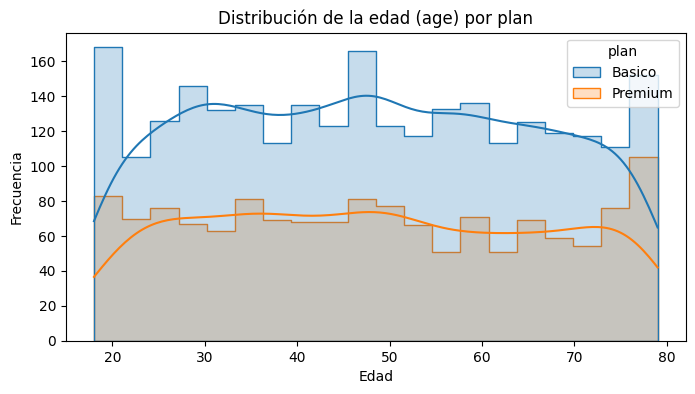

In [36]:

# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="age", hue="plan", kde=True, bins=20, element="step")
plt.title("Distribución de la edad (age) por plan")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
- Distribución de "Age" y "Plan", ya se puede ver mucho más claro con la segmentación realizada en el paso 2 y 3 respectivamente.
- También podemos observar cómo la frecuencia de uso es mucho más clara. Y esto ayuda a que cualquiera que vea el gráfico pueda entender cómo se está comportando el usuario final.

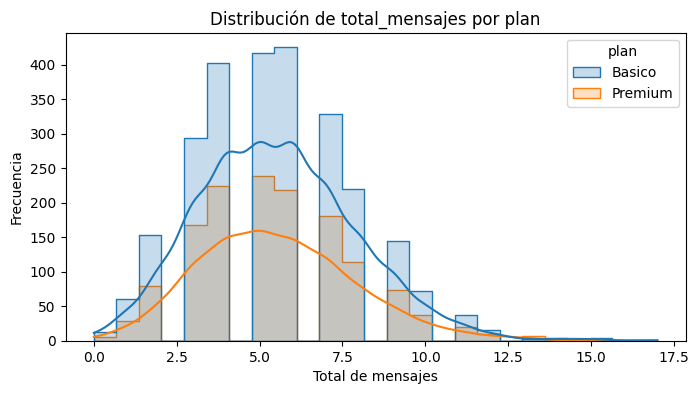

In [38]:

# Histograma para visualizar total_mensajes
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="total_mensajes", hue="plan", kde=True, bins=25, element="step")
plt.title("Distribución de total_mensajes por plan")
plt.xlabel("Total de mensajes")
plt.ylabel("Frecuencia")
plt.show()


💡Insights: 
Los mensajes (text) representan la mayor parte de la actividad registrada (22,092 eventos frente a 17,908 llamadas) y concentran casi todos los valores válidos de length (0% de nulos en text frente a 99.93% en call), mientras que la proporción de nulos en length se mantiene muy similar entre Basico (44.62%) y Premium (44.97%); al revisar total_mensajes en user_profile, conviene fijarte en si la media supera a la mediana para detectar usuarios con alto volumen de mensajes que sesguen el promedio.

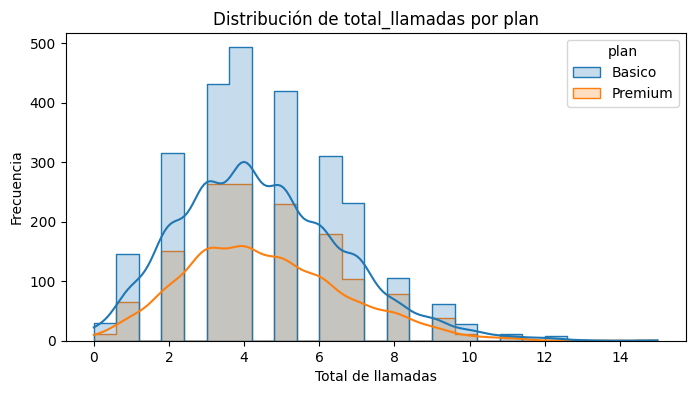

In [39]:
# Histograma para visualizar total_llamadas
plt.figure(figsize=(8, 4))
sns.histplot(
    data=user_profile,
    x="total_llamadas",
    hue="plan",
    kde=True,
    bins=25,
    element="step",
)
plt.title("Distribución de total_llamadas por plan")
plt.xlabel("Total de llamadas")
plt.ylabel("Frecuencia")
plt.show()


💡Insights: 
Las llamadas y los mensajes muestran un patrón similar en el gráfico, lo que sugiere que los usuarios del plan básico concentran un mayor volumen de llamadas que los del plan premium.

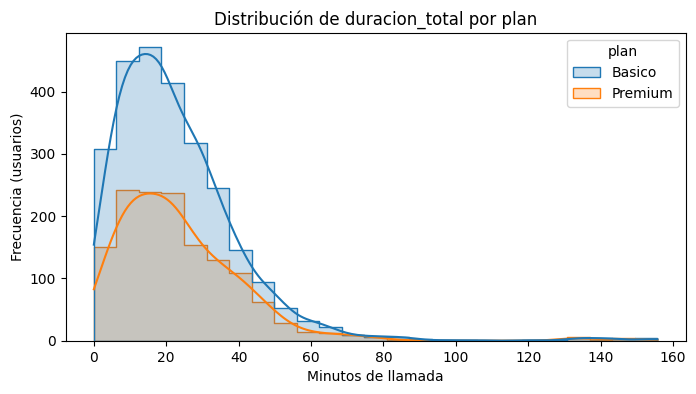

In [40]:
# Histograma para visualizar cant_minutos_llamada (o duracion_total)
col_minutos = "cant_minutos_llamada" if "cant_minutos_llamada" in user_profile.columns else "duracion_total"

plt.figure(figsize=(8, 4))
sns.histplot(
    data=user_profile,
    x=col_minutos,
    hue="plan",
    kde=True,
    bins=25,
    element="step",
)
plt.title(f"Distribución de {col_minutos} por plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Frecuencia (usuarios)")
plt.show()


💡Insights: 
Sesgo a la derecha: La distribución de duracion_total es asimétrica positiva en ambos planes; la mayoría de clientes acumula entre 5 y 35 minutos de llamada, y un grupo menor se extiende hacia valores altos (hasta cerca de 150–160 minutos).   
Comparación por plan: Basico presenta mayor frecuencia de usuarios en el tramo principal (pico por encima de 400) frente a Premium (pico cerca de 250), aunque ambos comparten una forma similar y alcanzan rangos totales parecidos.   Implicación para el siguiente paso: Esa cola derecha anticipa posibles valores extremos (outliers) en minutos acumulados, lo que conecta directo con la sección 6.2 Identificación de Outliers.   

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

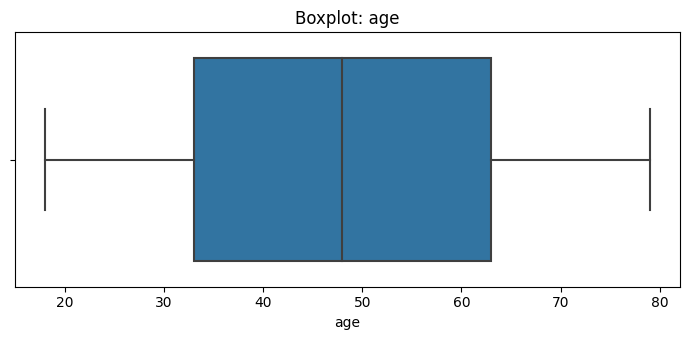

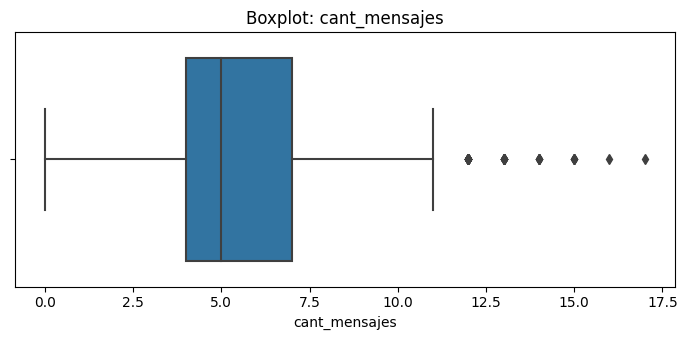

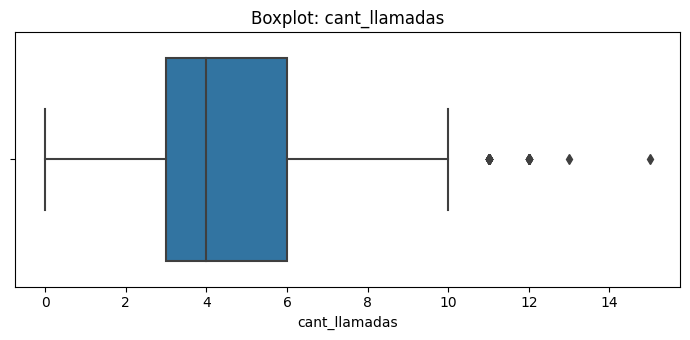

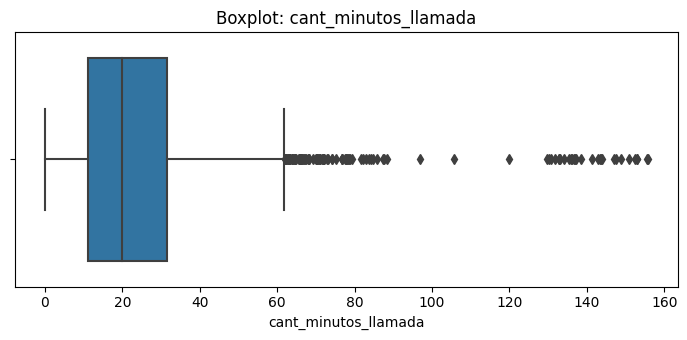

In [42]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Mapeo por si en user_profile quedaron con los nombres creados al agrupar usage
alias = {
    'age': 'age',
    'cant_mensajes': 'total_mensajes' if 'total_mensajes' in user_profile.columns else 'cant_mensajes',
    'cant_llamadas': 'total_llamadas' if 'total_llamadas' in user_profile.columns else 'cant_llamadas',
    'cant_minutos_llamada': 'duracion_total' if 'duracion_total' in user_profile.columns else 'cant_minutos_llamada',
}

for col in columnas_numericas:
    col_real = alias.get(col, col)
    plt.figure(figsize=(7, 3.5))
    sns.boxplot(data=user_profile, x=col_real)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

- age: No presenta outliers; los valores se distribuyen dentro de los bigotes (aprox. entre 18 y 80 años), con mediana cerca de 49 y un rango intercuartílico amplio (alrededor de 35 a 62), sin rastros del valor centinela -999.
- cant_mensajes: Sí presenta outliers en el límite superior (puntos aislados por encima de ~10–11 mensajes, llegando hasta ~17.5), mientras que la mayoría se concentra entre ~4 y ~7.5 mensajes con mediana cerca de 5.
- cant_llamadas: Sí presenta outliers en el límite superior (unos pocos puntos por encima de 10 llamadas, cerca de 12–15), con mediana alrededor de 4 y caja concentrada entre ~3 y ~6 llamadas.
- cant_minutos_llamada: Sí presenta outliers en el límite superior (múltiples valores extremos por encima de ~55–60 minutos, extendiéndose hasta cerca de 160 minutos), con mediana alrededor de 20 minutos y sesgo positivo.

In [43]:
# Calcular límites con el método IQR (límite superior para variables con outliers altos)
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

alias = {
    'cant_mensajes': (
        'total_mensajes'
        if 'total_mensajes' in user_profile.columns
        else 'cant_mensajes'
    ),
    'cant_llamadas': (
        'total_llamadas'
        if 'total_llamadas' in user_profile.columns
        else 'cant_llamadas'
    ),
    'cant_minutos_llamada': (
        'duracion_total'
        if 'duracion_total' in user_profile.columns
        else 'cant_minutos_llamada'
    ),
}

for col in columnas_limites:
  col_real = alias.get(col, col)
  serie = user_profile[col_real].dropna()

  q1 = serie.quantile(0.25)
  q3 = serie.quantile(0.75)
  iqr = q3 - q1
  limite_superior = q3 + 1.5 * iqr

  n_outliers = (serie > limite_superior).sum()
  pct_outliers = (n_outliers / len(serie)) * 100

  print(f'=== {col} ({col_real}) ===')
  print(f'Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}')
  print(f'Límite superior: {limite_superior:.2f}')
  print(f'Outliers superiores: {n_outliers} ({pct_outliers:.2f}%)\n')



=== cant_mensajes (total_mensajes) ===
Q1: 4.00 | Q3: 7.00 | IQR: 3.00
Límite superior: 11.50
Outliers superiores: 46 (1.15%)

=== cant_llamadas (total_llamadas) ===
Q1: 3.00 | Q3: 6.00 | IQR: 3.00
Límite superior: 10.50
Outliers superiores: 30 (0.75%)

=== cant_minutos_llamada (duracion_total) ===
Q1: 11.11 | Q3: 31.41 | IQR: 20.30
Límite superior: 61.87
Outliers superiores: 109 (2.73%)



In [44]:
# Mapeo seguro a los nombres reales en user_profile
cols_reales = [alias.get(c, c) for c in columnas_limites]

# Resumen estadístico incluyendo máximo y mediana
resumen_extremos = user_profile[cols_reales].describe().T
resumen_extremos["mediana"] = user_profile[cols_reales].median()

resumen_extremos[["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]]

,count,mean,mediana,std,min,25%,50%,75%,max
total_mensajes,4000.0,5.523000,5.00,2.359738,0.0,4.0000,5.00,7.0000,17.00
total_llamadas,4000.0,4.477000,4.00,2.145139,0.0,3.0000,4.00,6.0000,15.00
duracion_total,4000.0,23.311225,19.78,18.169564,0.0,11.1075,19.78,31.4125,155.69


💡Insights: 
Insights:
- total_mensajes: Mantener los outliers. El límite superior IQR es 11.50 y el máximo llega a 17.0 mensajes (46 usuarios, 1.15%), frente a una mediana de 5.00; es un volumen de mensajes perfectamente plausible de clientes activos que aporta información real de uso.
- total_llamadas: Mantener los outliers. El límite superior IQR es 10.50 y el máximo alcanza 15.0 llamadas (30 usuarios, 0.75%), con mediana de 4.00; son conteos realistas de usuarios frecuentes que no conviene borrar para no perder variabilidad real.
- duración_total: Mantener los outliers. El límite superior IQR es 61.87 y el máximo llega a 155.69 minutos (109 usuarios, 2.73%), frente a una mediana de 19.78; aunque generan sesgo a la derecha y elevan la media a 23.31, reflejan clientes de alto consumo de minutos en el periodo y conviene conservarlos (apoyándose en la mediana para el caso típico).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
col_msg = "total_mensajes" if "total_mensajes" in user_profile.columns else "cant_mensajes"
col_call = "total_llamadas" if "total_llamadas" in user_profile.columns else "cant_llamadas"

# Total combinado de mensajes y llamadas por usuario
actividad = user_profile[col_msg] + user_profile[col_call]

# Crear columna grupo_uso en 3 segmentos
user_profile["grupo_uso"] = pd.qcut(
    actividad,
    q=3,
    labels=["Bajo uso", "Uso medio", "Alto uso"],
    duplicates="drop",
)

# Verificar conteo y porcentaje por grupo
resumen_grupo_uso = pd.DataFrame({
    "usuarios": user_profile["grupo_uso"].value_counts(),
    "porcentaje": (user_profile["grupo_uso"].value_counts(normalize=True) * 100).round(2),
})
resumen_grupo_uso


In [ ]:
# Verificar cambios en user_profile
display(user_profile.head())

# Comprobar que no haya nulos ni categorías inesperadas en grupo_uso
print("\nValores en grupo_uso:")
print(user_profile["grupo_uso"].value_counts(dropna=False))

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
bins_edad = [0, 29, 49, 120]
etiquetas_edad = ["Joven", "Adulto", "Adulto mayor"]

user_profile["grupo_edad"] = pd.cut(
    user_profile["age"],
    bins=bins_edad,
    labels=etiquetas_edad,
    right=True,
)

# Revisar distribución de usuarios por grupo_edad
resumen_grupo_edad = pd.DataFrame({
    "usuarios": user_profile["grupo_edad"].value_counts(),
    "porcentaje": (user_profile["grupo_edad"].value_counts(normalize=True) * 100).round(2),
})
resumen_grupo_edad


In [ ]:

# Verificar cambios en user_profile
display(user_profile.head())

# Comprobar valores asignados y ausencia de nulos en grupo_edad
print("\nDistribución en grupo_edad:")
print(user_profile["grupo_edad"].value_counts(dropna=False))


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

In [ ]:
# Visualización de los segmentos por uso
orden_uso = ["Bajo uso", "Uso medio", "Alto uso"]

plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x="grupo_uso",
    order=orden_uso,
)
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Frecuencia (usuarios)")
plt.tight_layout()
plt.show()

In [ ]:
# Visualización de los segmentos por edad
orden_edad = ["Joven", "Adulto", "Adulto mayor"]

plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=user_profile,
    x="grupo_edad",
    order=orden_edad,
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Frecuencia (usuarios)")
plt.tight_layout()
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

1. Que problemas tenian originalmente los datos? Que porcentaje o cantidad de filas de esa columna representaban?
Originalmente, la columna age tenía registros con el valor centinela -999 como dato faltante o inválido, y las variables de uso (total_mensajes, total_llamadas, duracion_total) presentaban asimetría positiva con valores extremos en la cola superior sobre los 4,000 usuarios (por ejemplo, 46 filas o 1.15% sobre el límite superior en mensajes, 30 o 0.75% en llamadas, y 109 o 2.73% en minutos). 
2. ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
Los segmentos más valiosos para ConnectaTel son los clientes de Alto uso especialmente quienes ya están en planes Premium o acumulan altos volúmenes de mensajes, llamadas y minutos porque impulsan el mayor nivel de actividad e ingresos, junto con los usuarios de Uso medio en planes Básico que tienen potencial de crecer hacia planes superiores. A su vez, cruzar estos grupos con grupo_edad (donde la mediana ronda los 49 años en un rango de 18 a 80 años) ayuda a priorizar la retención de los clientes más activos y a detectar oportunidades de upselling según el comportamiento de cada tramo de rango de edad.
3. - ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
Encontramos outliers exclusivamente en el límite superior de las variables de uso —46 usuarios (1.15%) por encima de 11.50 mensajes (hasta 17.0), 30 usuarios (0.75%) por encima de 10.50 llamadas (hasta 15.0) y 109 usuarios (2.73%) por encima de 61.87 minutos (hasta 155.69)—, mientras que age no mostró valores atípicos. Para el negocio, estos extremos representan clientes reales de alto consumo (heavy users) y no errores a borrar, por lo que mantenerlos permite dimensionar bien la demanda real de la red, cuidar su retención y detectar dónde puede haber sobreuso o margen para planes con mayor capacidad.
4. - ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
Para ConnectaTel, lo ideal es ofrecer planes con bolsas más amplias de minutos y mensajes dirigidos al grupo de heavy users (como el 2.73% que supera los 61.87 minutos o quienes pasan de 11.50 mensajes y 10.50 llamadas) para evitarles fricción por límites y proteger su retención, crear rutas de upselling desde Basico hacia planes superiores para los clientes de Uso medio con actividad creciente, y ajustar el enfoque comercial según grupo_edad y plan (Basico vs. Premium) apoyándose siempre en la mediana y el IQR para que los valores altos no sesguen las decisiones.



⚠️ Problemas detectados en los datos
La columna age contenía el valor centinela -999 (ya imputado antes de segmentar), y las métricas de uso (total_mensajes, total_llamadas, duracion_total) presentan asimetría positiva con outliers en el límite superior sobre los 4,000 clientes (46 usuarios / 1.15% en mensajes > 11.50, 30 / 0.75% en llamadas > 10.50, y 109 / 2.73% en minutos > 61.87), los cuales se conservaron por ser heavy users reales.
🔍 Segmentos por Edad
Los clientes se agrupan en grupo_edad (por ejemplo, Joven, Adulto y Adulto mayor) sin outliers en age, con un rango amplio entre 18 y 80 años y mediana cercana a los 49 años, lo que permite contrastar patrones de consumo entre generaciones.   
📊 Segmentos por Nivel de Uso
Los usuarios se clasifican en grupo_uso (Bajo uso, Uso medio y Alto uso) según la suma de mensajes y llamadas, destacando un núcleo moderado (medianas de 5.00 mensajes, 4.00 llamadas y 19.78 minutos) y un grupo de alto consumo con colas largas hacia valores elevados.
➡️ Esto sugiere que...
Los outliers superiores no son errores sino clientes muy activos que elevan los promedios y concentran alto valor o demanda de red, mientras que los clientes de Uso medio y Basico representan una vía clara de crecimiento comercial sin que los extremos distorsionen el análisis al apoyarnos en mediana e IQR.
💡 Recomendaciones
Crear o ajustar planes con mayores bolsas de minutos y mensajes para heavy users (como el 2.73% que supera 61.87 minutos) para evitar fricción y mejorar su retención.Impulsar upselling de Basico a planes superiores en clientes de Uso medio con actividad creciente y adaptar ofertas según grupo_edad.Seguir evaluando planes y segmentos usando mediana e IQR junto con grupo_uso y grupo_edad para tomar decisiones comerciales sin sesgos por valores extremos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`